# [01-2] 전처리 · 머신러닝 · 성능평가 — EOL 최종검사 불량 선별

**K-뉴딜 아카데미 스마트팩토리 캡스톤 · 공통 미니 프로젝트 (1~2회차 · 4개 팀 동일 데이터)**

### 오늘의 목표

1. 1편에서 정한 **정제 규칙을 코드로 고정**한다
2. **검사 전에 알 수 있는 변수만** 골라 모델을 만든다 (데이터 누출 방지)
3. **로지스틱 회귀 · 의사결정나무 · 랜덤포레스트** 3가지를 학습한다
4. **혼동행렬 · Recall · Precision · ROC-AUC** 로 비교한다
5. **임계값**을 조정해 현장 조건에 맞춘다

### 머신러닝이란

| | 규칙을 누가 만드나 |
|---|---|
| 전통적 방식 | **사람**: "토크가 27 미만이면 추가검사" |
| 머신러닝 | **데이터**: 여러 변수의 조합을 자동으로 찾음 |

머신러닝의 강점은 **여러 변수를 동시에** 보는 것입니다.
약점은 **원인을 알려 주지 않는다**는 것입니다(상관만 학습합니다).

---

## 1. 준비 — 라이브러리와 한글 폰트

| 도구 | 역할 |
|---|---|
| `pandas` (pd) | 표 데이터 처리 (엑셀에 해당) |
| `numpy` (np) | 숫자 계산 |
| `matplotlib` (plt) · `seaborn` (sns) | 그래프 |
| `scikit-learn` | 머신러닝 |

아래 셀은 **한 번만** 실행하면 됩니다.

준비 완료 | pandas 2.2.3 | Colab: True
한글 폰트 : NanumGothic


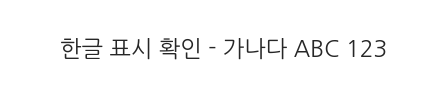

위 그림의 글자가 □□□ 로 보이면 [런타임 > 런타임 다시 시작] 후 이 셀을 다시 실행하세요.


In [19]:
# [준비 셀] 내용을 자세히 이해할 필요는 없습니다. 실행만 하세요.
# 라이브러리 불러오기 + 한글 폰트 설정
import os, sys, glob, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score)
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

# -----------------------------------------------------------------------------
# 한글 폰트 설정
#   ※ 순서 주의: seaborn 스타일을 먼저 적용해야 한다.
#      sns.set_style() 이 글꼴 설정을 sans-serif 로 덮어쓰기 때문이다.
# -----------------------------------------------------------------------------
sns.set_style("whitegrid")                      # ① 스타일 먼저

from matplotlib import font_manager as fm

KOREAN_FONTS = ["NanumGothic", "NanumBarunGothic", "Malgun Gothic", "AppleGothic",
                "Apple SD Gothic Neo", "Noto Sans CJK KR", "Noto Sans KR"]


def find_korean_font():
    """설치된 한글 폰트를 찾고, 없으면 Colab에서 나눔폰트를 설치한다."""
    have = {f.name for f in fm.fontManager.ttflist}
    for n in KOREAN_FONTS:
        if n in have:
            return n
    if IN_COLAB:                                 # 나눔폰트 설치 후 다시 찾기
        print("한글 폰트를 설치하는 중입니다... (20초 정도 걸립니다)")
        os.system("apt-get install -y fonts-nanum > /dev/null 2>&1")
        os.system(f"{sys.executable} -m pip install -q koreanize-matplotlib")
        for path in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):
            fm.fontManager.addfont(path)
        have = {f.name for f in fm.fontManager.ttflist}
        for n in KOREAN_FONTS:
            if n in have:
                return n
    return None


FONT = find_korean_font()                        # ② 폰트 나중에
if FONT:
    plt.rcParams["font.family"] = FONT
    plt.rcParams["font.sans-serif"] = [FONT] + list(plt.rcParams["font.sans-serif"])
plt.rcParams["axes.unicode_minus"] = False       # 음수 기호(-) 깨짐 방지
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("준비 완료 | pandas", pd.__version__, "| Colab:", IN_COLAB)
print("한글 폰트 :", FONT if FONT else "찾지 못함")

# ③ 자가진단 - 아래 그림에 한글이 보이면 정상입니다
plt.figure(figsize=(5, 0.9))
plt.text(0.5, 0.5, "한글 표시 확인 - 가나다 ABC 123",
         ha="center", va="center", fontsize=15)
plt.axis("off")
plt.show()
print("위 그림의 글자가 □□□ 로 보이면 [런타임 > 런타임 다시 시작] 후 이 셀을 다시 실행하세요.")

---

## 2. 데이터 불러오기

Colab은 구글의 임시 컴퓨터에서 돌아가므로 **데이터 파일을 올려 줘야** 합니다.
아래 셀이 흔한 경로를 먼저 찾아보고, 못 찾으면 **업로드 창**을 띄웁니다.
(드라이브를 쓰려면 맨 위 2줄의 `#` 을 지우세요.)

- 사용할 파일: `K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx`

In [20]:
# [데이터 적재 셀] 파일을 찾아서 읽어 오는 코드입니다. 실행만 하세요.
# from google.colab import drive
# drive.mount('/content/drive')

DATA_FILE = "K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx"
SEARCH_DIRS = [os.environ.get("KNEWDEAL_DATA_DIR", ""), ".", "..", "../..", "/content",
               "/content/drive/MyDrive", "/content/drive/MyDrive/K뉴딜"]

DATA_PATH = None
for d in SEARCH_DIRS:                      # ① 정확한 파일명으로 찾기
    if d and os.path.exists(os.path.join(d, DATA_FILE)):
        DATA_PATH = os.path.join(d, DATA_FILE)
        break
if DATA_PATH is None:                      # ② 키워드로 찾기
    for d in SEARCH_DIRS:
        hits = glob.glob(os.path.join(d, "*MiniCase*")) if d else []
        if hits:
            DATA_PATH = sorted(hits)[0]
            break
if DATA_PATH is None and IN_COLAB:         # ③ 직접 업로드
    from google.colab import files
    DATA_PATH = list(files.upload().keys())[0]

print("데이터 경로:", DATA_PATH)
df_raw = pd.read_excel(DATA_PATH, sheet_name="MiniCase_Data")
print("크기(행, 열):", df_raw.shape)
df_raw.head(3)

데이터 경로: ./K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정 (1).xlsx
크기(행, 열): (1200, 20)


,record_id,timestamp,shift,line_id,product_model,equipment_id,operator_group,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,inspection_result,defect_type,inspection_time_sec,rework_flag,rework_time_min,final_disposition
0,R00001,2026-07-01 21:00:25,야간,L1,P1,M04,G01,31.460,5.980,51.400,35.200,2.700,0,1.000,합격,NaN,37,N,0,합격
1,R00002,2026-07-02 12:12:10,주간,L2,P2,M04,G02,32.370,5.660,50.600,38.600,2.590,0,0.915,합격,NaN,42,N,0,합격
2,R00003,2026-07-03 10:03:12,주간,L1,P1,M03,G03,30.260,5.680,49.400,39.500,2.270,1,1.044,합격,NaN,46,N,0,합격


In [21]:
# 토크 결측 복원에 쓸 '센서로그' 시트도 함께 읽는다
sensor_log = pd.read_excel(DATA_PATH, sheet_name="센서로그")
print("센서로그:", sensor_log.shape)
sensor_log

센서로그: (12, 4)


,record_id,timestamp,torque_nm_restored,근거
0,R00845,2026-07-08 15:37:46,30.650,교육용 합성 센서로그: 정상범위 복원 실습
1,R00268,2026-07-20 09:45:48,31.590,교육용 합성 센서로그: 정상범위 복원 실습
2,R00351,2026-07-10 10:38:06,32.010,교육용 합성 센서로그: 정상범위 복원 실습
3,R00740,2026-07-27 10:47:47,31.040,교육용 합성 센서로그: 정상범위 복원 실습
4,R00655,2026-07-04 14:11:22,30.450,교육용 합성 센서로그: 정상범위 복원 실습
5,R00472,2026-07-07 14:01:46,29.200,교육용 합성 센서로그: 정상범위 복원 실습
6,R00892,2026-07-24 08:02:46,31.960,교육용 합성 센서로그: 정상범위 복원 실습
7,R00196,2026-07-10 13:02:22,30.880,교육용 합성 센서로그: 정상범위 복원 실습
8,R00349,2026-07-08 13:32:59,31.760,교육용 합성 센서로그: 정상범위 복원 실습
9,R00290,2026-07-11 14:47:03,30.650,교육용 합성 센서로그: 정상범위 복원 실습


---

## 3. 데이터 정제

### 이 데이터의 정제 규칙 (1편 결과로 확정)

| 항목 | 처리 | 이유 |
|---|---|---|
| `torque_nm` 결측 12건 | **센서로그에서 복원** | 원본 로그가 있으면 추정보다 항상 낫다 |
| `vibration_mm_s` 결측 18건 | **설비별 중앙값**으로 채움 | 설비마다 진동 수준이 다르다 |
| `defect_type` 결측 1,152건 | **그대로 둠** | 합격품은 불량유형이 없다(구조적 결측) |

> 손으로 엑셀을 고치지 않고 **코드로 고정**하는 이유: 한 달 뒤에도 "무엇을 어떻게 고쳤는지"
> 그대로 재현할 수 있기 때문입니다.

In [22]:
def clean_data(d, sensor_log):
    """꼭 필요한 정제만 수행한다."""
    d = d.copy()

    # ① 토크 결측 → 센서로그의 복원값으로 채운다 (record_id로 연결)
    restore = sensor_log.set_index("record_id")["torque_nm_restored"]
    d["torque_nm"] = d["torque_nm"].fillna(d["record_id"].map(restore))

    # ② 진동 결측 → 같은 설비의 중앙값으로 채운다
    d["vibration_mm_s"] = d["vibration_mm_s"].fillna(
        d.groupby("equipment_id")["vibration_mm_s"].transform("median"))

    # ③ defect_type(불량유형)은 구조적 결측이므로 그대로 둔다
    return d


df = clean_data(df_raw, sensor_log)
print("정제 후 남은 결측:")
print(df.isna().sum()[lambda s: s > 0].to_string())

정제 후 남은 결측:
defect_type    1152


---

## 4. 입력변수 고르기 — 데이터 누출 막기

**데이터 누출(data leakage)**: 예측 시점에는 알 수 없는 값을 모델에 넣는 것.
시험 문제지 뒤에 답이 인쇄된 상태로 공부하는 것과 같습니다.
**연습은 100점, 실전은 0점**이 됩니다.

### 쓸 수 없는 변수 (검사 후에 생기는 값)

| 변수 | 이유 |
|---|---|
| `defect_type` | 불량유형. 불합격 판정이 난 뒤에 기록된다. 값이 있으면 그 제품은 이미 불합격이다 |
| `inspection_time_sec` | 검사 소요시간. 검사를 해야 생기는 값이다 |
| `rework_flag` | 재작업 여부. 불합격 이후의 조치다 |
| `rework_time_min` | 재작업시간. 불합격 이후의 조치다 |
| `final_disposition` | 최종처분(합격/재작업후합격). 사실상 정답의 복사본이다 |

### 쓸 수 있는 변수 (검사 전에 이미 존재)
범주형: `shift`, `line_id`, `product_model`, `equipment_id`, `operator_group`
수치형: `torque_nm`, `pressure_bar`, `cycle_time_sec`, `temperature_c`, `vibration_mm_s`, `downtime_min`, `energy_kwh`

> 성능이 비현실적으로 높으면(정확도 99%, AUC 0.99) **먼저 누출을 의심하세요.**
> 실무에서 가장 흔한 실패 원인입니다.

In [23]:
df.shape

(1200, 20)

In [24]:
df.columns

Index(['record_id', 'timestamp', 'shift', 'line_id', 'product_model',
       'equipment_id', 'operator_group', 'torque_nm', 'pressure_bar',
       'cycle_time_sec', 'temperature_c', 'vibration_mm_s', 'downtime_min',
       'energy_kwh', 'inspection_result', 'defect_type', 'inspection_time_sec',
       'rework_flag', 'rework_time_min', 'final_disposition'],
      dtype='object')

In [26]:
df['inspection_result'] = df['inspection_result'].map({'합격': 0, '불합격': 1})
display(df['inspection_result'])

,inspection_result
0,0
1,0
2,0
3,0
4,0
...,...
1195,0
1196,0
1197,0
1198,0


In [34]:
df.columns

Index(['record_id', 'timestamp', 'shift', 'line_id', 'product_model',
       'equipment_id', 'operator_group', 'torque_nm', 'pressure_bar',
       'cycle_time_sec', 'temperature_c', 'vibration_mm_s', 'downtime_min',
       'energy_kwh', 'inspection_result', 'defect_type', 'inspection_time_sec',
       'rework_flag', 'rework_time_min', 'final_disposition'],
      dtype='object')

In [33]:
df.final_disposition.value_counts()

,count
final_disposition,
합격,1152
재작업후합격,48


In [45]:
features = df.columns.difference(['inspection_result', 'final_disposition','timestamp' ])
X = df[features]
y = df['inspection_result']


In [46]:
# 수치형 변수 및 범주형 변수의 전처리
numeric_features = ['torque_nm', 'pressure_bar', 'cycle_time_sec', 'temperature_c', 'vibration_mm_s', 'downtime_min', 'energy_kwh']
categorical_features = ['shift', 'line_id', 'product_model', 'equipment_id', 'operator_group']

In [47]:
X[:3]

,cycle_time_sec,defect_type,downtime_min,energy_kwh,equipment_id,inspection_time_sec,line_id,operator_group,pressure_bar,product_model,record_id,rework_flag,rework_time_min,shift,temperature_c,torque_nm,vibration_mm_s
0,51.400,NaN,0,1.000,M04,37,L1,G01,5.980,P1,R00001,N,0,야간,35.200,31.460,2.700
1,50.600,NaN,0,0.915,M04,42,L2,G02,5.660,P2,R00002,N,0,주간,38.600,32.370,2.590
2,49.400,NaN,1,1.044,M03,46,L1,G03,5.680,P1,R00003,N,0,주간,39.500,30.260,2.270


In [48]:
sc = StandardScaler()
X[numeric_features] = sc.fit_transform(X[numeric_features])

In [53]:
X[numeric_features][:3]

,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh
0,0.748,1.526,-0.483,-1.627,1.696,-1.017,0.835
1,1.231,-1.223,-0.714,0.041,1.424,-1.017,-0.618
2,0.111,-1.051,-1.062,0.482,0.633,0.983,1.588


In [ ]:
# 나중에 inference 시 새로운 데이터에 대해서... sc.transform(Xnew)

In [50]:
sc.scale_

array([1.88360056, 0.1164257 , 3.45034104, 2.03836944, 0.40431117,
       0.49993055, 0.05847887])

In [57]:
X[categorical_features][:3]

,shift,line_id,product_model,equipment_id,operator_group
0,야간,L1,P1,M04,G01
1,주간,L2,P2,M04,G02
2,주간,L1,P1,M03,G03


In [56]:
pd.get_dummies(X[categorical_features])*1

,shift_야간,shift_주간,line_id_L1,line_id_L2,product_model_P1,product_model_P2,equipment_id_M01,equipment_id_M02,equipment_id_M03,equipment_id_M04,operator_group_G01,operator_group_G02,operator_group_G03,operator_group_G04,operator_group_G05,operator_group_G06
0,1,0,1,0,1,0,0,0,0,1,1,0,0,0,0,0
1,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,0
2,0,1,1,0,1,0,0,0,1,0,0,0,1,0,0,0
3,1,0,1,0,1,0,0,0,0,1,0,0,0,1,0,0
4,0,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,0,1,1,0,1,0,1,0,0,0,0,1,0,0,0,0
1196,0,1,0,1,0,1,0,1,0,0,0,0,1,0,0,0
1197,0,1,1,0,1,0,0,0,1,0,0,0,0,1,0,0
1198,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0


In [59]:
x1 = np.arange(24).reshape(4,6)
x1

array([[ 0,  1,  2,  3,  4,  5],
       [ 6,  7,  8,  9, 10, 11],
       [12, 13, 14, 15, 16, 17],
       [18, 19, 20, 21, 22, 23]])

In [62]:
x2 = np.arange(24,48).reshape(4,6)
x2

array([[24, 25, 26, 27, 28, 29],
       [30, 31, 32, 33, 34, 35],
       [36, 37, 38, 39, 40, 41],
       [42, 43, 44, 45, 46, 47]])

In [63]:
np.hstack([x1,x2])

array([[ 0,  1,  2,  3,  4,  5, 24, 25, 26, 27, 28, 29],
       [ 6,  7,  8,  9, 10, 11, 30, 31, 32, 33, 34, 35],
       [12, 13, 14, 15, 16, 17, 36, 37, 38, 39, 40, 41],
       [18, 19, 20, 21, 22, 23, 42, 43, 44, 45, 46, 47]])

In [64]:
np.vstack([x1,x2])

array([[ 0,  1,  2,  3,  4,  5],
       [ 6,  7,  8,  9, 10, 11],
       [12, 13, 14, 15, 16, 17],
       [18, 19, 20, 21, 22, 23],
       [24, 25, 26, 27, 28, 29],
       [30, 31, 32, 33, 34, 35],
       [36, 37, 38, 39, 40, 41],
       [42, 43, 44, 45, 46, 47]])

In [68]:
x1+x2

array([[24, 26, 28, 30, 32, 34],
       [36, 38, 40, 42, 44, 46],
       [48, 50, 52, 54, 56, 58],
       [60, 62, 64, 66, 68, 70]])

In [69]:
type(x1)

numpy.ndarray

In [73]:
df1 = pd.DataFrame(x1, columns=['a','b','c','d','e','f'])
df2 = pd.DataFrame(x2, columns=['a','b','c','d','e','f'])
df1

,a,b,c,d,e,f
0,0,1,2,3,4,5
1,6,7,8,9,10,11
2,12,13,14,15,16,17
3,18,19,20,21,22,23


In [76]:
pd.concat([df1,df2], axis=1)

,a,b,c,d,e,f,a,b,c,d,e,f
0,0,1,2,3,4,5,24,25,26,27,28,29
1,6,7,8,9,10,11,30,31,32,33,34,35
2,12,13,14,15,16,17,36,37,38,39,40,41
3,18,19,20,21,22,23,42,43,44,45,46,47


In [52]:
X[categorical_features][:3]

,shift,line_id,product_model,equipment_id,operator_group
0,야간,L1,P1,M04,G01
1,주간,L2,P2,M04,G02
2,주간,L1,P1,M03,G03


In [41]:
X[:3]

,cycle_time_sec,defect_type,downtime_min,energy_kwh,equipment_id,inspection_time_sec,line_id,operator_group,pressure_bar,product_model,record_id,rework_flag,rework_time_min,shift,temperature_c,torque_nm,vibration_mm_s
0,-0.483,NaN,-1.017,0.835,M04,37,L1,G01,1.526,P1,R00001,N,0,야간,-1.627,0.748,1.696
1,-0.714,NaN,-1.017,-0.618,M04,42,L2,G02,-1.223,P2,R00002,N,0,주간,0.041,1.231,1.424
2,-1.062,NaN,0.983,1.588,M03,46,L1,G03,-1.051,P1,R00003,N,0,주간,0.482,0.111,0.633


In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=19, stratify=y)

In [31]:
X_train[:10]

,cycle_time_sec,defect_type,downtime_min,energy_kwh,equipment_id,final_disposition,inspection_time_sec,line_id,operator_group,pressure_bar,product_model,record_id,rework_flag,rework_time_min,shift,temperature_c,timestamp,torque_nm,vibration_mm_s
1115,58.400,NaN,0,0.867,M04,합격,36,L2,G06,5.840,P2,R01116,N,0,주간,38.900,2026-07-31 12:11:46,27.380,2.680
992,50.500,NaN,1,1.020,M03,합격,42,L1,G03,5.870,P1,R00993,N,0,주간,39.100,2026-07-01 10:14:05,31.260,1.510
775,57.200,NaN,0,0.935,M02,합격,42,L2,G02,5.660,P2,R00776,N,0,주간,36.900,2026-07-01 12:48:21,30.460,2.400
163,48.000,NaN,0,0.984,M02,합격,42,L2,G02,5.830,P2,R00164,N,0,주간,41.700,2026-07-09 15:31:10,30.380,2.190
736,47.300,NaN,1,0.978,M04,합격,35,L2,G05,5.600,P2,R00737,N,0,주간,39.000,2026-07-24 08:03:34,31.970,2.170
180,50.800,NaN,0,1.014,M04,합격,37,L2,G01,5.890,P2,R00181,N,0,주간,37.500,2026-07-26 09:46:02,28.240,1.430
867,47.800,NaN,0,0.855,M02,합격,46,L2,G04,5.840,P2,R00868,N,0,주간,38.700,2026-07-31 09:19:23,31.330,2.650
317,58.200,NaN,0,1.033,M03,합격,44,L1,G06,5.830,P1,R00318,N,0,야간,39.500,2026-07-08 00:43:16,26.140,1.850
634,52.900,NaN,1,0.907,M02,합격,36,L2,G05,5.680,P2,R00635,N,0,야간,37.200,2026-07-15 22:11:36,27.960,2.010
875,47.500,NaN,0,0.878,M02,합격,39,L2,G06,5.840,P2,R00876,N,0,주간,39.100,2026-07-08 15:58:02,28.090,1.450


In [12]:
df["target"] = (df['inspection_result'] == '불합격').astype(int)          # 1 = 불합격(추가확인 대상)

CAT = ["shift", "line_id", "product_model", "equipment_id", "operator_group"]
NUM = [
    "torque_nm", "pressure_bar", "cycle_time_sec", "temperature_c", "vibration_mm_s",
    "downtime_min", "energy_kwh"
]

X = df[CAT + NUM]
y = df["target"]
print("입력 변수:", len(CAT), "개(범주형) +", len(NUM), "개(수치형)")
print("양성:", int(y.sum()), "건 /", len(y), "건 =", f"{y.mean()*100:.2f}%")

입력 변수: 5 개(범주형) + 7 개(수치형)
양성: 48 건 / 1200 건 = 4.00%


In [13]:
X.shape, y.shape

((1200, 12), (1200,))

In [18]:
df_raw.columns

Index(['record_id', 'timestamp', 'shift', 'line_id', 'product_model',
       'equipment_id', 'operator_group', 'torque_nm', 'pressure_bar',
       'cycle_time_sec', 'temperature_c', 'vibration_mm_s', 'downtime_min',
       'energy_kwh', 'inspection_result', 'defect_type', 'inspection_time_sec',
       'rework_flag', 'rework_time_min', 'final_disposition'],
      dtype='object')

In [14]:
X.columns

Index(['shift', 'line_id', 'product_model', 'equipment_id', 'operator_group',
       'torque_nm', 'pressure_bar', 'cycle_time_sec', 'temperature_c',
       'vibration_mm_s', 'downtime_min', 'energy_kwh'],
      dtype='object')

---

## 5. 데이터 분리 · 전처리 · 모델 학습

### ① 학습용 / 평가용 분리
학습에 쓴 데이터로 평가하면 항상 성적이 좋습니다(시험문제를 미리 본 셈).
그래서 **75%는 학습, 25%는 평가**로 나눕니다.
`stratify=y` 는 양쪽의 불량 비율을 똑같이 맞춰 줍니다(불량이 드물 때 필수).

### ② 전처리 2가지
- **스케일링**: 변수마다 단위가 다르므로(온도 35~42, 토크 25~34) 평균 0·표준편차 1로 맞춤
- **원핫인코딩**: 문자(`주간`/`야간`)를 0/1 열로 바꿈

`Pipeline` 으로 묶으면 **학습 데이터에서만 기준을 배우도록** 자동으로 보장됩니다.

### ③ 모델 3가지

| 모델 | 방식 | 특징 |
|---|---|---|
| 로지스틱 회귀 | 변수에 가중치를 곱해 더한 뒤 확률로 변환 | **해석이 쉽다** |
| 의사결정나무 | 스무고개처럼 질문을 이어가며 나눔 | **그림으로 볼 수 있다** |
| 랜덤포레스트 | 나무 300그루의 다수결 | **성능이 가장 좋은 편** |

`class_weight="balanced"` 는 **드문 쪽(불량)을 틀렸을 때 벌점을 더 크게** 줍니다.
불량이 4%뿐이라 이 옵션이 없으면 모델이 "전부 합격"이라고 답해 버립니다.

In [11]:
X_train

,shift,line_id,product_model,equipment_id,operator_group,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh
9,주간,L1,P1,M01,G04,32.390,5.640,55.600,36.700,2.330,0,0.891
80,야간,L2,P2,M01,G03,27.510,5.670,54.600,38.000,1.700,1,1.022
328,야간,L1,P1,M04,G05,28.460,5.760,49.400,39.600,2.590,0,0.982
1143,야간,L2,P2,M01,G04,28.900,5.690,50.700,41.300,2.420,0,0.872
5,주간,L2,P2,M02,G06,31.190,5.900,51.100,38.800,2.510,0,1.031
...,...,...,...,...,...,...,...,...,...,...,...,...
958,야간,L2,P2,M01,G05,29.240,5.980,55.400,37.200,1.800,1,0.990
105,야간,L2,P2,M02,G04,30.340,5.600,56.500,40.200,2.040,0,0.857
1171,주간,L2,P2,M02,G02,31.090,5.640,54.400,41.100,1.530,0,0.919
497,야간,L1,P1,M04,G06,28.670,5.700,55.400,37.300,1.440,1,0.959


In [8]:
SEED = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
print(f"학습 {len(X_train)}건(양성 {int(y_train.sum())}) / "
      f"평가 {len(X_test)}건(양성 {int(y_test.sum())})")

# 전처리: 수치형은 결측 채우고 스케일링, 범주형은 결측 채우고 원핫인코딩
pre = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUM),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore",
                                               sparse_output=False))]), CAT),
])

# 모델 3가지를 전처리와 묶어서 학습
models = {
    "로지스틱회귀": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "의사결정나무": DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                           class_weight="balanced", random_state=SEED),
    "랜덤포레스트": RandomForestClassifier(n_estimators=300, max_depth=8,
                                           min_samples_leaf=5, class_weight="balanced",
                                           random_state=SEED),
}
for name, clf in models.items():
    models[name] = Pipeline([("pre", pre), ("clf", clf)]).fit(X_train, y_train)
    print(name, "학습 완료")

학습 900건(양성 36) / 평가 300건(양성 12)
로지스틱회귀 학습 완료
의사결정나무 학습 완료
랜덤포레스트 학습 완료


---

## 6. 성능평가 — 혼동행렬과 4가지 지표

### 혼동행렬

| | 예측: 합격 | 예측: 불합격 |
|---|---|---|
| **실제 합격** | TN | **FP (헛경보)** → 불필요한 추가검사 |
| **실제 불합격** | **FN (놓침)** → 불량 유출 | TP (제대로 잡음) |

**FN과 FP의 비용은 다릅니다.** 보통 놓침(FN)이 훨씬 비쌉니다.

### 지표 4가지

| 지표 | 계산 | 질문 |
|---|---|---|
| Accuracy | (TP+TN)/전체 | 전체 중 몇 % 맞혔나 → **불균형이면 믿으면 안 됨** |
| **Recall** | TP/(TP+FN) | **불량 중 몇 %를 잡았나** |
| **Precision** | TP/(TP+FP) | **경보 중 몇 %가 진짜였나** |
| F1 | 둘의 조화평균 | 균형 |

Recall과 Precision은 **맞바꾸는 관계**입니다. 경보를 많이 울리면 Recall↑ Precision↓.
어느 쪽이 중요한지는 **데이터가 아니라 현장이** 정합니다.

In [9]:
def evaluate(model, name, threshold=0.5, show=True):
    """혼동행렬과 지표를 계산한다."""
    proba = model.predict_proba(X_test)[:, 1]        # 불합격일 확률
    pred = (proba >= threshold).astype(int)          # 임계값으로 0/1 결정
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    if show:
        print(f"[{name}]  TP {tp} / FN {fn} / FP {fp} / TN {tn}")
        print(f"   Accuracy {accuracy_score(y_test, pred):.3f} | "
              f"Recall {recall_score(y_test, pred, zero_division=0):.3f} | "
              f"Precision {precision_score(y_test, pred, zero_division=0):.3f} | "
              f"AUC {roc_auc_score(y_test, proba):.3f}")
    return {"모델": name, "Accuracy": accuracy_score(y_test, pred),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "AUC": roc_auc_score(y_test, proba),
            "TP": tp, "FN": fn, "FP": fp, "TN": tn}


results = [evaluate(m, n) for n, m in models.items()]

# '전부 합격'이라고 답하는 기준선과 비교
base = {"모델": "기준선(전부 합격)", "Accuracy": 1 - y_test.mean(), "Recall": 0,
        "Precision": 0, "F1": 0, "AUC": 0.5,
        "TP": 0, "FN": int(y_test.sum()), "FP": 0, "TN": int((y_test == 0).sum())}
display(pd.DataFrame([base] + results).set_index("모델").round(3))
print("기준선은 정확도가 가장 높지만 불량을 한 건도 못 잡는다(TP=0). 그래서 Recall을 본다.")

[로지스틱회귀]  TP 6 / FN 6 / FP 95 / TN 193
   Accuracy 0.663 | Recall 0.500 | Precision 0.059 | AUC 0.661
[의사결정나무]  TP 4 / FN 8 / FP 52 / TN 236
   Accuracy 0.800 | Recall 0.333 | Precision 0.071 | AUC 0.690
[랜덤포레스트]  TP 1 / FN 11 / FP 0 / TN 288
   Accuracy 0.963 | Recall 0.083 | Precision 1.000 | AUC 0.785


,Accuracy,Recall,Precision,F1,AUC,TP,FN,FP,TN
모델,,,,,,,,,
기준선(전부 합격),0.960,0.000,0.000,0.000,0.500,0,12,0,288
로지스틱회귀,0.663,0.500,0.059,0.106,0.661,6,6,95,193
의사결정나무,0.800,0.333,0.071,0.118,0.690,4,8,52,236
랜덤포레스트,0.963,0.083,1.000,0.154,0.785,1,11,0,288


기준선은 정확도가 가장 높지만 불량을 한 건도 못 잡는다(TP=0). 그래서 Recall을 본다.


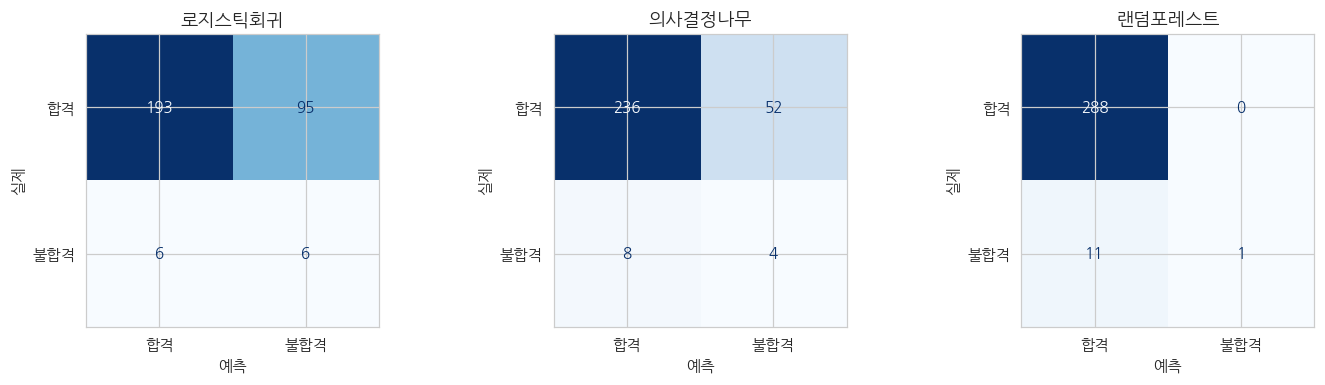

In [10]:
# 혼동행렬 그림
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, m) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, m.predict(X_test), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["합격", "불합격"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
    ax.set_xlabel("예측"); ax.set_ylabel("실제")
plt.tight_layout()
plt.show()

---

## 7. ROC 곡선과 AUC

모델은 0/1이 아니라 **확률**을 출력합니다. "몇 점 이상을 불량으로 볼까"가 **임계값**입니다.

**ROC 곡선**은 임계값을 0부터 1까지 바꿔 가며 그린 그림입니다.
가로축 = 헛경보율, 세로축 = Recall. **왼쪽 위에 가까울수록 좋습니다.**

**AUC**는 곡선 아래 면적입니다. 의미는 **"불량 하나와 합격 하나를 뽑았을 때,
모델이 불량에 더 높은 점수를 줄 확률"** 입니다.

| AUC | 0.5 | 0.7 | 0.8 | 0.9 이상 |
|---|---|---|---|---|
| 해석 | 무작위 | 쓸 만함 | 좋음 | **누출 의심** |

In [ ]:
plt.figure(figsize=(6, 5))
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="무작위 (AUC=0.5)")
plt.xlabel("헛경보율 (FP / 실제 합격)")
plt.ylabel("Recall (TP / 실제 불합격)")
plt.title("ROC 곡선")
plt.legend()
plt.show()

---

## 8. 임계값 조정 — 모델을 바꾸지 않고 운영점 바꾸기

기본 임계값은 0.5입니다. 이 숫자를 내리면 **경보가 늘고 Recall이 올라갑니다.**

| 임계값 | 경보 수 | Recall | Precision |
|---|---|---|---|
| 높게 (0.7) | 적음 | 낮음 | 높음 |
| 낮게 (0.2) | 많음 | **높음** | 낮음 |

**현장 제약을 먼저 정하고 임계값을 고르는 것**이 올바른 순서입니다.
("추가검사는 하루 50건까지 가능" → 그에 맞는 임계값 선택)

In [ ]:
# 임계값과 무관한 지표(AUC)로 기준 모델을 고른다
best_name = max(results, key=lambda r: r["AUC"])["모델"]
best_model = models[best_name]
proba = best_model.predict_proba(X_test)[:, 1]
print("기준 모델:", best_name, "(AUC가 가장 높음 = 순위를 가장 잘 매김)")

rows = []
for th in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (proba >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"임계값": th, "추가검사 건수": int(pred.sum()), "TP(잡음)": tp,
                 "FN(놓침)": fn, "FP(헛경보)": fp,
                 "Recall": recall_score(y_test, pred, zero_division=0),
                 "Precision": precision_score(y_test, pred, zero_division=0)})
th_tbl = pd.DataFrame(rows)
display(th_tbl.round(3))

plt.figure(figsize=(7, 4))
plt.plot(th_tbl["임계값"], th_tbl["Recall"], "o-", label="Recall (놓치지 않는 비율)")
plt.plot(th_tbl["임계값"], th_tbl["Precision"], "s-", label="Precision (경보 적중률)")
plt.axvline(0.5, color="gray", ls="--", label="기본값 0.5")
plt.xlabel("임계값"); plt.legend()
plt.title("임계값에 따른 맞바꿈(trade-off)")
plt.show()

---

## 9. 규칙 기반 판정과 비교 — Baseline v0 / v1

현장에서 실제로 쓰는 방식은 **간단한 규칙**입니다.

| 버전 | 규칙 |
|---|---|
| **v0** | 체결토크 < 27 또는 > 33 |
| **v1** | v0 **또는** (야간조 AND M03) |

규칙은 **설명이 쉽고, 바로 적용할 수 있고, 고장나지 않습니다.**
머신러닝과 **같은 기준(혼동행렬)으로 공정하게** 비교해 봅시다.
**규칙으로 충분하다면 규칙을 쓰는 것이 옳은 선택입니다.**

In [ ]:
actual = (df["inspection_result"] == "불합격").astype(int)
v0 = ((df["torque_nm"] < 27) | (df["torque_nm"] > 33)).astype(int)
v1 = (v0 | ((df["shift"] == "야간") & (df["equipment_id"] == "M03"))).astype(int)

rows = []
for name, rule in [("v0: 토크 규격 이탈", v0), ("v1: 토크 이탈 또는 야간M03", v1)]:
    tn, fp, fn, tp = confusion_matrix(actual, rule, labels=[0, 1]).ravel()
    rows.append({"규칙": name, "추가확인": int(rule.sum()), "TP": tp, "FN": fn,
                 "FP": fp, "TN": tn,
                 "Recall(%)": round(tp / (tp + fn) * 100, 1),
                 "Precision(%)": round(tp / (tp + fp) * 100, 1),
                 "Accuracy(%)": round((tp + tn) / len(actual) * 100, 1)})
display(pd.DataFrame(rows).set_index("규칙"))

print("v0 → v1: 불량 15건을 더 잡는 대가로 추가검사가 45건 늘었다.")
print("이 맞바꿈을 현장이 받아들일 수 있는지가 의사결정의 핵심이다.")

---

## 10. 의사결정나무 보기 + 놓친 사례 확인

나무를 그림으로 보면 **그대로 현장 점검 규칙**이 됩니다.
그리고 **놓친 사례(FN)** 를 직접 보는 것이 다음 개선의 출발점입니다.

In [ ]:
# 깊이 3으로 줄여서 읽기 쉽게
simple_tree = Pipeline([
    ("pre", pre),
    ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=20,
                                   class_weight="balanced", random_state=SEED)),
]).fit(X_train, y_train)

names = [n.replace("num__", "").replace("cat__", "")
         for n in simple_tree.named_steps["pre"].get_feature_names_out()]
plt.figure(figsize=(18, 7))
plot_tree(simple_tree.named_steps["clf"], feature_names=names,
          class_names=["합격", "불합격"], filled=True, rounded=True,
          fontsize=9, impurity=False)
plt.title("의사결정나무 (왼쪽=조건 참, 오른쪽=거짓)")
plt.show()

In [ ]:
# 놓친 사례(FN) 살펴보기 - 왜 못 잡았을까?
pred = (proba >= 0.3).astype(int)                     # 임계값 0.3 기준
check = X_test.copy()
check["실제"] = y_test.values
check["예측확률"] = proba.round(3)
fn_rows = check[(check["실제"] == 1) & (pred == 0)]

print(f"놓친 사례(FN) {len(fn_rows)}건")
display(fn_rows.head())
print("놓친 제품들이 '평범한 값'을 가지고 있다면, 지금 변수로는 구분이 어렵다는 뜻이다.")
print("→ 새로운 변수를 만들거나(3편) 센서를 추가해야 한다는 근거가 된다.")

---

## 11. 정리

### 꼭 기억할 5가지

| # | 원칙 |
|---|---|
| 1 | **정확도만 보지 않는다** — 불량이 4%면 아무것도 안 해도 96% |
| 2 | **놓침(FN)과 헛경보(FP)의 비용은 다르다** — 어느 쪽이 비싼지는 현장이 정한다 |
| 3 | **성능이 너무 좋으면 누출을 의심한다** — 검사 후 변수를 넣지 않았는지 확인 |
| 4 | **임계값은 운영 정책이다** — 모델을 바꾸지 않고도 경보 수를 조절할 수 있다 |
| 5 | **간단한 규칙이 이길 수도 있다** — 머신러닝을 쓰는 것이 목적이 아니다 |

### 3편에서 할 것
- 모델이 **어떤 변수를 보고** 판단했는가 (가중치 · 특성중요도)
- **현장 지식으로 새 변수**를 만들면 성능이 오를까 (특성공학)
- 변수를 **몇 개로 줄여도** 되는가 (특성선택 · PCA)

---

## 연습문제 / 생각해 볼 질문

아래 문항은 정답을 맞히는 시험이 아니라, **발표자료에 쓸 문장을 만드는 연습**입니다.
코드를 조금씩 바꿔 보고, 결과를 한 문장으로 정리해 보세요.

1. `THRESHOLD` 를 0.5 → 0.3 → 0.2 로 바꿔 보고, 불량 탐지 건수(TP)와 헛경보(FP)가 어떻게 변하는지 적으세요. 품질팀이라면 어떤 값을 고르겠습니까?
2. 규칙 v1(토크 이탈 또는 야간M03)과 머신러닝 모델의 혼동행렬을 비교하세요. 어느 쪽을 현장에 먼저 적용하겠습니까?
3. `final_disposition`(최종처분)을 특성에 추가해 학습해 보세요. 성능이 거의 100%가 나옵니다. 왜 이것이 '성공'이 아닌지 설명하세요.